# Where should Picnic expand next in Germany?
## SQL queries, the scoring model, and a robustness check

Run each cell in order with **Shift + Enter**. Read the text above each cell first, it explains what the code does.

## Load the data
Colab forgets uploaded files when the session restarts, so upload `Picnic_Expansion_Data_Table_final.xlsx` once more.

In [12]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving Picnic_Expansion_Data_Table.xlsx to Picnic_Expansion_Data_Table.xlsx
Uploaded: ['Picnic_Expansion_Data_Table.xlsx']


In [13]:
import glob
import pandas as pd

path = glob.glob("*Data_Table_final*.xlsx")[0]   # finds the file even if its name has "(1)" in it
df = pd.read_excel(path, sheet_name="Cities")
print("Rows and columns:", df.shape)
df[["City", "State", "Density_per_km2", "Disposable_income_EUR", "Avg_household_size", "Share_aged_25_44"]].head()

Rows and columns: (30, 10)


,City,State,Density_per_km2,Disposable_income_EUR,Avg_household_size,Share_aged_25_44
0,Freiburg im Breisgau,Baden-Württemberg,1514.356630,27158,2.0,0.322326
1,Ulm,Baden-Württemberg,1069.494524,32974,2.1,0.306501
2,Pforzheim,Baden-Württemberg,1280.908163,26823,2.2,0.275609
3,Reutlingen,Baden-Württemberg,1337.037887,30012,2.2,0.256037
4,Augsburg,Bavaria,2019.604905,25528,1.9,0.310710


## Create the SQL database
SQL is the language analysts use to ask questions of a database. Here we create a small database that lives in memory
(it disappears when the session ends, which is fine) and copy our table into it. SQLite is the database engine, and its
SQL is almost the same as the MySQL you already know.

In [14]:
import sqlite3

conn = sqlite3.connect(":memory:")
df.drop(columns=["Notes_source"]).to_sql("cities", conn, index=False, if_exists="replace")

def q(sql):
    """Run a SQL query and show the result as a table."""
    return pd.read_sql_query(sql, conn)

q("SELECT COUNT(*) AS number_of_cities FROM cities")

,number_of_cities
0,30


## SQL queries
**Question 1.** Which 5 cities are the most densely populated? (Dense cities make delivery cheaper.)

In [23]:
q('''
SELECT City, State, ROUND(Density_per_km2) AS density_per_km2
FROM cities
ORDER BY Density_per_km2 DESC
LIMIT 5
''')

,City,State,density_per_km2
0,Frankfurt am Main,Hesse,3058.0
1,Mainz,Rhineland-Palatinate,2227.0
2,Ludwigshafen am Rhein,Rhineland-Palatinate,2216.0
3,Kiel,Schleswig-Holstein,2076.0
4,Fürth,Bavaria,2037.0


**Question 2.** How do the federal states compare? `GROUP BY` puts the cities of each state together,
and `AVG` takes the average of each group.

In [24]:
q('''
SELECT State,
       COUNT(*)                          AS n_cities,
       ROUND(AVG(Disposable_income_EUR)) AS avg_income_eur,
       ROUND(AVG(Density_per_km2))       AS avg_density
FROM cities
GROUP BY State
ORDER BY avg_income_eur DESC
''')

,State,n_cities,avg_income_eur,avg_density
0,Baden-Württemberg,4,29242.0,1300.0
1,Bavaria,5,29218.0,1692.0
2,North Rhine-Westphalia,5,27392.0,1426.0
3,Brandenburg,1,27311.0,978.0
4,Hesse,2,26881.0,2465.0
5,Lower Saxony,1,26174.0,997.0
6,Rhineland-Palatinate,4,25760.0,1617.0
7,Thuringia,2,25618.0,877.0
8,Schleswig-Holstein,1,25058.0,2076.0
9,Saarland,1,25033.0,1075.0


**Question 3.** Which cities are both dense **and** well off? (More than 1,500 people per km² and more than 26,000 EUR income per person.)

In [25]:
q('''
SELECT City, State, ROUND(Density_per_km2) AS density_per_km2, Disposable_income_EUR AS income_eur
FROM cities
WHERE Density_per_km2 > 1500 AND Disposable_income_EUR > 26000
ORDER BY Density_per_km2 DESC
''')

,City,State,density_per_km2,income_eur
0,Frankfurt am Main,Hesse,3058.0,29442
1,Mainz,Rhineland-Palatinate,2227.0,27153
2,Fürth,Bavaria,2037.0,32437
3,Regensburg,Bavaria,1900.0,29370
4,Solingen,North Rhine-Westphalia,1776.0,28618
5,Freiburg im Breisgau,Baden-Württemberg,1514.0,27158


## Scoring model
We want **one score per city** that says how attractive it is for Picnic. There are four steps:

1. **Rescale** each indicator to a 0 to 1 scale, so that different units can be added together. The lowest city gets 0, the highest gets 1.
   Formula: `(value - lowest) / (highest - lowest)`.
2. **Choose weights** that say how important each indicator is. The weights must add up to 1 (100%).
3. **Add up** each rescaled value times its weight. That is the score.
4. **Rank** the cities by score.

**Why these four indicators, and why these weights?** (This is a business judgement, so change the weights if you disagree.)

| Indicator | Weight | Reason |
|---|---|---|
| Density (people per km²) | 35% | Picnic's delivery vans run fixed routes, so many customers close together means lower cost per order. The most important driver. |
| Disposable income | 30% | Shows how much people can spend on groceries. |
| Share aged 25 to 44 | 20% | The age group most used to ordering groceries on an app. |
| Average household size | 15% | Bigger households place bigger orders, but it is the weakest of the four signals. |

For all four indicators, a **higher value is better** for Picnic.

In [18]:
indicators = ["Density_per_km2", "Disposable_income_EUR", "Share_aged_25_44", "Avg_household_size"]

base_weights = {
    "Density_per_km2":       0.35,
    "Disposable_income_EUR": 0.30,
    "Share_aged_25_44":      0.20,
    "Avg_household_size":    0.15,
}

def minmax(series):
    """Rescale a column to 0..1 (lowest = 0, highest = 1)."""
    return (series - series.min()) / (series.max() - series.min())

def score_cities(data, weights):
    """Return the cities with a score and a rank, best city first."""
    assert abs(sum(weights.values()) - 1) < 1e-9, "Weights must add up to 1"
    out = data[["City", "State"] + list(weights)].copy()
    out["Score"] = 0.0
    for col, w in weights.items():
        out["Score"] += w * minmax(data[col])
    out["Rank"] = out["Score"].rank(ascending=False, method="min").astype(int)
    return out.sort_values("Rank").reset_index(drop=True)

ranking = score_cities(df, base_weights)
ranking[["Rank", "City", "State", "Score"]].head(10).round(3)

,Rank,City,State,Score
0,1,Frankfurt am Main,Hesse,0.792
1,2,Fürth,Bavaria,0.677
2,3,Mainz,Rhineland-Palatinate,0.602
3,4,Ulm,Baden-Württemberg,0.600
4,5,Regensburg,Bavaria,0.573
5,6,Erlangen,Bavaria,0.560
6,7,Reutlingen,Baden-Württemberg,0.514
7,8,Freiburg im Breisgau,Baden-Württemberg,0.505
8,9,Bergisch Gladbach,North Rhine-Westphalia,0.495
9,10,Augsburg,Bavaria,0.491


## Top 10 cities

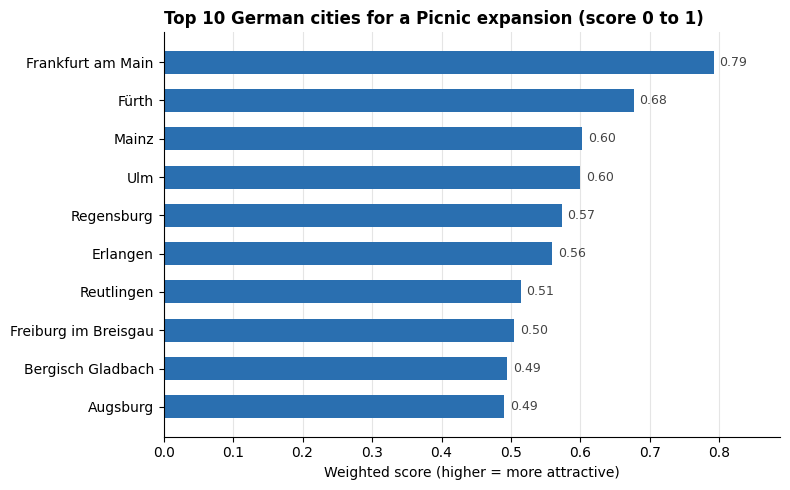

In [19]:
import matplotlib.pyplot as plt

top10 = ranking.head(10).iloc[::-1]          # reversed so that rank 1 is drawn at the top

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top10["City"], top10["Score"], color="#2A6FB0", height=0.6)
for bar, value in zip(bars, top10["Score"]):
    ax.text(value + 0.008, bar.get_y() + bar.get_height() / 2, f"{value:.2f}", va="center", fontsize=9, color="#444444")

ax.set_title("Top 10 German cities for a Picnic expansion (score 0 to 1)", loc="left", fontsize=12, fontweight="bold")
ax.set_xlabel("Weighted score (higher = more attractive)")
ax.set_xlim(0, top10["Score"].max() * 1.12)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.xaxis.grid(True, color="#E5E5E5")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Sensitivity check
Weights are judgement calls. A good analyst checks whether the answer changes if the weights change.
If the same cities stay at the top under very different weights, the recommendation is **robust**.

In [20]:
scenarios = {
    "Base weights":    base_weights,
    "Density focus":   {"Density_per_km2": 0.50, "Disposable_income_EUR": 0.20, "Share_aged_25_44": 0.15, "Avg_household_size": 0.15},
    "Income focus":    {"Density_per_km2": 0.20, "Disposable_income_EUR": 0.50, "Share_aged_25_44": 0.15, "Avg_household_size": 0.15},
    "Equal weights":   {"Density_per_km2": 0.25, "Disposable_income_EUR": 0.25, "Share_aged_25_44": 0.25, "Avg_household_size": 0.25},
    "Families focus":  {"Density_per_km2": 0.30, "Disposable_income_EUR": 0.25, "Share_aged_25_44": 0.15, "Avg_household_size": 0.30},
}

rows = []
for name, w in scenarios.items():
    r = score_cities(df, w)
    rows.append({"Scenario": name, "Top 1": r.loc[0, "City"], "Top 2": r.loc[1, "City"], "Top 3": r.loc[2, "City"]})
pd.DataFrame(rows)

,Scenario,Top 1,Top 2,Top 3
0,Base weights,Frankfurt am Main,Fürth,Mainz
1,Density focus,Frankfurt am Main,Fürth,Mainz
2,Income focus,Fürth,Ulm,Frankfurt am Main
3,Equal weights,Frankfurt am Main,Fürth,Ulm
4,Families focus,Frankfurt am Main,Fürth,Ulm


In [21]:
from collections import Counter

counts = Counter()
for name, w in scenarios.items():
    counts.update(score_cities(df, w).head(3)["City"])

pd.DataFrame(counts.most_common(), columns=["City", "Times in top 3 (out of 5 scenarios)"])

,City,Times in top 3 (out of 5 scenarios)
0,Frankfurt am Main,5
1,Fürth,5
2,Ulm,3
3,Mainz,2


**How to read this:** cities that appear in the top 3 in most scenarios are the safest recommendation.
Cities that only appear in one scenario depend on a specific weighting.

## Robustness check
Five cities use district values for income and household size (Reutlingen, Göttingen, Bergisch Gladbach, Recklinghausen, Saarbrücken),
because the sources have no separate figure for the city. Do the top cities change if we leave those five out?

In [22]:
district_cities = ["Reutlingen", "Göttingen", "Bergisch Gladbach", "Recklinghausen", "Saarbrücken"]
without = score_cities(df[~df["City"].isin(district_cities)], base_weights)

comparison = pd.DataFrame({
    "All 30 cities":      ranking.head(5)["City"].values,
    "Without the 5 district-value cities": without.head(5)["City"].values,
}, index=[1, 2, 3, 4, 5])
comparison.index.name = "Rank"
comparison

,All 30 cities,Without the 5 district-value cities
Rank,,
1,Frankfurt am Main,Frankfurt am Main
2,Fürth,Fürth
3,Mainz,Mainz
4,Ulm,Ulm
5,Regensburg,Regensburg


## Limits of this analysis
- The data years are mixed: population and area 2021, income 2023, household size May 2022, age share mostly 2023 (2021 for five cities).
- The age band is 25 to 44, because the source has no 25 to 55 band.
- Five cities (Reutlingen, Göttingen, Bergisch Gladbach, Recklinghausen, Saarbrücken) use district values for income and household size.
- The weights are assumptions about what drives delivery economics, not measured effects.
- The model has no data on delivery costs, competitors or local demand. It is a first screen, not a decision.